In [76]:
import pandas as pd
import matplotlib.pyplot as plt

In [77]:
df = pd.read_csv('weather_classification_data.csv')

In [80]:
df.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           13200 non-null  float64
 1   Humidity              13200 non-null  int64  
 2   Wind Speed            13200 non-null  float64
 3   Precipitation (%)     13200 non-null  float64
 4   Cloud Cover           13200 non-null  object 
 5   Atmospheric Pressure  13200 non-null  float64
 6   UV Index              13200 non-null  int64  
 7   Season                13200 non-null  object 
 8   Visibility (km)       13200 non-null  float64
 9   Location              13200 non-null  object 
 10  Weather Type          13200 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.1+ MB


In [82]:
df.shape

(13200, 11)

In [83]:
df.isna().sum()

Temperature             0
Humidity                0
Wind Speed              0
Precipitation (%)       0
Cloud Cover             0
Atmospheric Pressure    0
UV Index                0
Season                  0
Visibility (km)         0
Location                0
Weather Type            0
dtype: int64

In [84]:
df.duplicated().sum()

0

In [86]:
# Selecting the categorical columns for encoding
cat_cols = df.select_dtypes(include='object').columns
cat_cols

Index(['Cloud Cover', 'Season', 'Location', 'Weather Type'], dtype='object')

In [87]:
for c in cat_cols:
    print(df[c].value_counts())
    print('******************\n')

Cloud Cover
overcast         6090
partly cloudy    4560
clear            2139
cloudy            411
Name: count, dtype: int64
******************

Season
Winter    5610
Spring    2598
Autumn    2500
Summer    2492
Name: count, dtype: int64
******************

Location
inland      4816
mountain    4813
coastal     3571
Name: count, dtype: int64
******************

Weather Type
Rainy     3300
Cloudy    3300
Sunny     3300
Snowy     3300
Name: count, dtype: int64
******************



#### Encoding

In [97]:
df['Cloud Cover'] = df['Cloud Cover'].map({'clear':1, 'partly cloudy':2, 'cloudy':3, 'overcast':4})

In [98]:
df['Season'] = df['Season'].map({'Winter':1, 'Spring':2, 'Autumn':3, 'Summer':4})

In [99]:
df['Location'] = df['Location'].map({'inland':1, 'mountain':2, 'coastal':3})

In [100]:
df['Weather Type'] = df['Weather Type'].map({'Rainy':1, 'Cloudy':2, 'Sunny':3, 'Snowy':4})

In [101]:
df.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,2,1010.82,2,1,3.5,1,1
1,39.0,96,8.5,71.0,2,1011.43,7,2,10.0,1,2
2,30.0,64,7.0,16.0,1,1018.72,5,2,5.5,2,3
3,38.0,83,1.5,82.0,1,1026.25,7,2,1.0,3,3
4,27.0,74,17.0,66.0,4,990.67,1,1,2.5,2,1


#### Data Splitting

In [102]:
X = df.drop('Weather Type', axis=1)
y = df['Weather Type']

In [103]:
from sklearn.model_selection import train_test_split

In [104]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [105]:
X_train.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location
7759,42.0,20,6.5,17.0,2,1015.09,9,4,10.0,3
9505,43.0,45,6.0,19.0,1,1022.35,8,4,7.0,2
11189,14.0,50,8.0,14.0,2,1011.71,4,3,8.5,3
10127,2.0,96,13.5,89.0,2,982.42,1,1,1.5,1
5657,23.0,30,5.0,83.0,2,888.58,12,1,8.5,3


In [106]:
X_train.shape, y_train.shape

((9900, 10), (9900,))

In [107]:
X_test.shape, y_test.shape

((3300, 10), (3300,))

#### Scaling

In [108]:
from sklearn.preprocessing import StandardScaler

In [109]:
scaler = StandardScaler()

In [110]:
X_train_scaled = scaler.fit_transform(X_train)

In [111]:
X_test_scaled = scaler.transform(X_test)

In [112]:
X_train_scaled[0]

array([ 1.32115072, -2.40238498, -0.48003547, -1.14419795, -0.66401551,
        0.24017788,  1.2972333 ,  1.61455456,  1.34268083,  1.39070881])

#### Model Building

In [113]:
from sklearn.neighbors import KNeighborsClassifier

In [118]:
model = KNeighborsClassifier()

In [122]:
model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [123]:
train_score = model.score(X_train_scaled, y_train)
train_score

0.925959595959596

In [124]:
test_score = model.score(X_test_scaled, y_test)
test_score

0.9015151515151515

#### Compare the predictions with the actual values

In [125]:
y_pred = model.predict(X_train_scaled)

In [140]:
y_pred

array([3, 3, 2, ..., 3, 2, 1], dtype=int64)

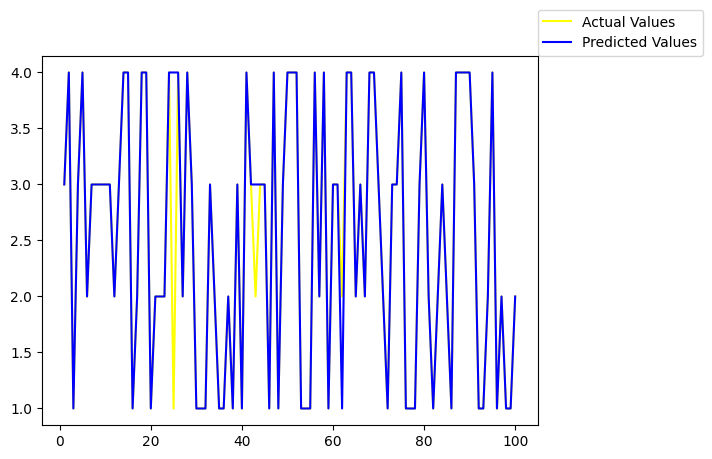

In [139]:
plt.plot(range(1,101), y_train[100:200], label='Actual Values', color='yellow')
plt.plot(range(1,101), y_pred[100:200], label='Predicted Values', color='blue')
plt.legend(loc=(1,1))
plt.show()

#### Hyperparameter 'K'

In [141]:
train_score = []
test_score = []

for k in range(1,21):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    train_score.append(model.score(X_train_scaled, y_train))
    test_score.append(model.score(X_test_scaled, y_test))
    

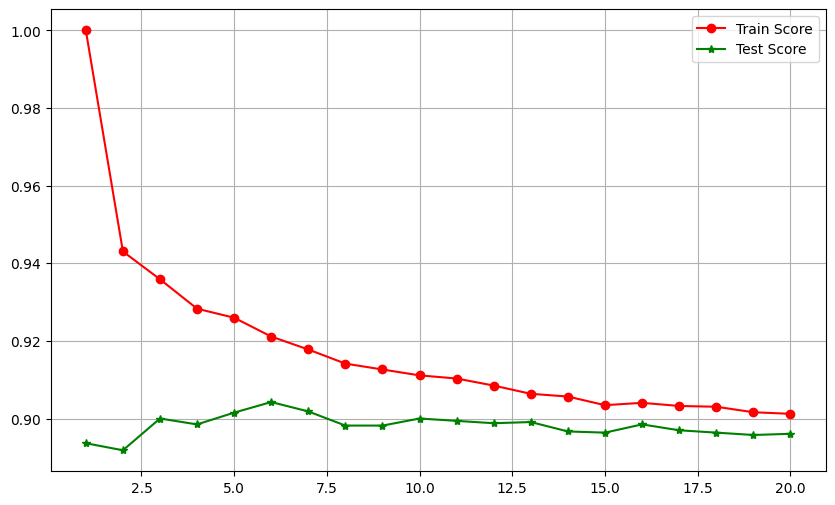

In [142]:
plt.figure(figsize=(10,6))
plt.plot(range(1,21), train_score, color='red', label='Train Score', marker='o')
plt.plot(range(1,21), test_score, color='green', label='Test Score', marker='*')
plt.legend()
plt.grid()
plt.show()

Best value of k to be taken as 6

In [144]:
model = KNeighborsClassifier(n_neighbors=6)

In [145]:
model.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=6)

In [146]:
train_score = model.score(X_train_scaled, y_train)
train_score

0.9211111111111111

In [147]:
test_score = model.score(X_test_scaled, y_test)
test_score

0.9042424242424243

#### Performance Metrics

In [148]:
from sklearn.metrics import precision_score, recall_score

In [149]:
y_test_pred = model.predict(X_test_scaled)

In [150]:
print("Precision:", precision_score(y_test, y_test_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_test_pred, average='weighted'))

Precision: 0.9062493595153269
Recall: 0.9042424242424243
